### Specifications:

    sampling frequency = 200 Hz
    useful frequencies = 0-5 Hz
    unwanted frequencies = 60-100 Hz
    maximum passband error = 5%
    minimum stopband attenuation = 15 dB
    maximum group delay = 15 ms

##### Design A : FIR moving-average filter

filter length = 3
passband error = %0.814
stopband attenuation (dB)= 9.542
group delay (ms)= 5.0
---------
filter length = 5
passband error = %2.431
stopband attenuation (dB)= 12.140
group delay (ms)= 10.0
---------
filter length = 7
passband error = %4.827
stopband attenuation (dB)= 15.975
group delay (ms)= 15.0
---------
filter length = 9
passband error = %7.966
stopband attenuation (dB)= 18.537
group delay (ms)= 20.0
---------


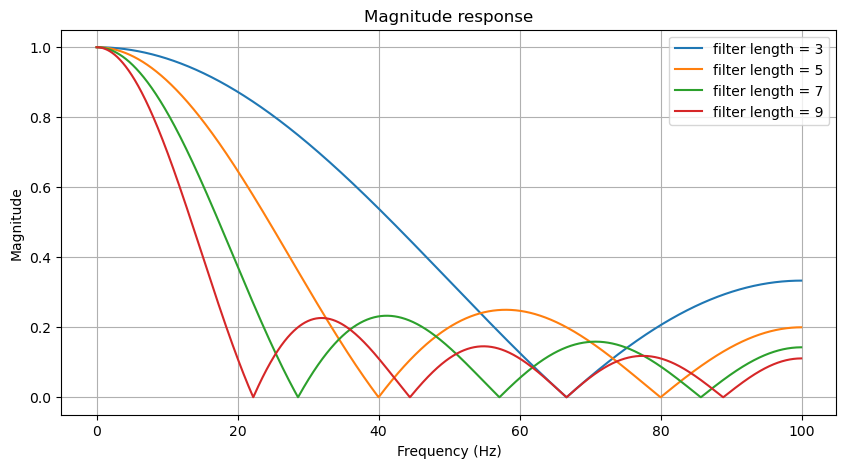

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import lfilter, freqz, group_delay

fs = 200
#FIR possible lengths
lengths = [3, 5, 7, 9]
plt.figure(figsize=(10, 5))
for M in lengths:
    b = np.ones(M) / M
    f, H = freqz(b, [1], worN=2048, fs=fs)
    magnitude = np.abs(H)
    plt.plot(f, magnitude, label = f"filter length = {M}")
    passband = f <= 5
    passband_error = np.max(np.abs(magnitude[passband] - 1)) * 100
    stopband = f >= 60
    stopband_att_dB = -20 * np.log10((np.max(magnitude[stopband])))
    #symmetric FIR filter
    group_delay_samples = (M - 1) / 2
    group_delay_ms = (group_delay_samples / fs) * 1000
    print(f"filter length = {M}")
    print(f"passband error = %{passband_error:.3f}")
    print(f"stopband attenuation (dB)= {stopband_att_dB:.3f}")
    print(f"group delay (ms)= {group_delay_ms}")
    print("---------")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("Magnitude response")
plt.legend()
plt.grid(True)
plt.show()
    


Selected filter is M = 7, which means it has seven coefficients and order 6

From the graph:

    Increasing the filter length improves stopband attnuation
    Increasing filter length increases passband error
    Increasing filter length increases group delay

#### Design B : first-order IIR filter

alpha = 0.5
passband error = %2.357
stopband attenuation (dB)= 7.950
-----------
alpha = 0.7
passband error = %8.331
stopband attenuation (dB)= 13.297
-----------
alpha = 0.8
passband error = %18.039
stopband attenuation (dB)= 17.273
-----------
alpha = 0.9
passband error = %44.088
stopband attenuation (dB)= 23.742
-----------


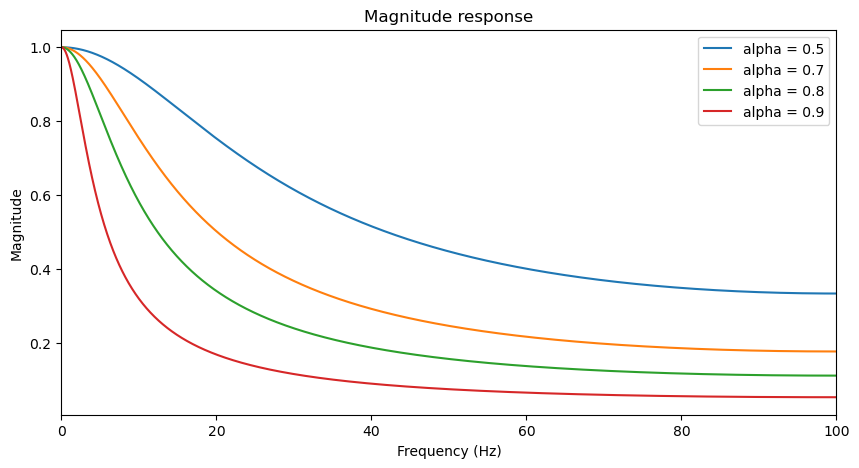

In [11]:
alphas = [0.5, 0.7, 0.8, 0.9]
plt.figure(figsize=(10, 5))
for alpha in alphas:
    b_iir = np.array([1 - alpha])
    a_iir = np.array([1, -alpha])
    _, H = freqz(b_iir, a_iir, worN=2048, fs=fs)
    magnitude = np.abs(H)
    plt.plot(f, magnitude, label = f"alpha = {alpha}")
    passband = f <= 5
    passband_error = np.max(np.abs(magnitude[passband] - 1)) * 100
    stopband = f >= 60
    stopband_att_dB = -20 * np.log10((np.max(magnitude[stopband])))
    print(f"alpha = {alpha}")
    print(f"passband error = %{passband_error:.3f}")
    print(f"stopband attenuation (dB)= {stopband_att_dB:.3f}")
    print("-----------")

plt.legend()
plt.xlim(0, 100)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("Magnitude response")
plt.show() 


None of these IIR filters satisfies both amplitude requirements

What graph shows:

    When alpha increases, the filter suppresses high-frequency noise more strongly
    However, the filter also attenuates useful frequencies between 0 and 5 Hz more strongly
    Therefore, improving stopband attenuation comes at the cost of increasing passband error

alpha = 0.5 : Maximum group delay: 5.00 ms
alpha = 0.7 : Maximum group delay: 11.67 ms
alpha = 0.8 : Maximum group delay: 20.00 ms
alpha = 0.9 : Maximum group delay: 45.00 ms


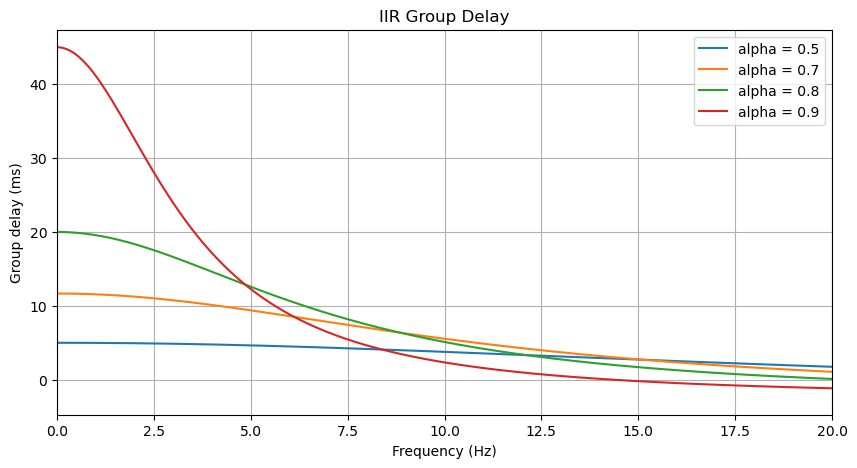

In [14]:
#IIR group delay
from scipy.signal import group_delay

alphas = [0.5, 0.7, 0.8, 0.9]
plt.figure(figsize=(10, 5))
for alpha in alphas:
    b_iir = np.array([1 - alpha])
    a_iir = np.array([1, -alpha])
    f_gd, gd_samples = group_delay((b_iir, a_iir), w = 2048, fs=fs)
    gd_ms = gd_samples / fs * 1000
    passband = f_gd <= 5
    max_delay_ms = np.max(gd_ms[passband])
    print(f"alpha = {alpha} : Maximum group delay: {max_delay_ms:.2f} ms")
    plt.plot(f_gd, gd_ms, label = f"alpha = {alpha}")
    
plt.xlabel("Frequency (Hz)")
plt.ylabel("Group delay (ms)")
plt.title("IIR Group Delay")
plt.xlim(0, 20)
plt.grid(True)
plt.legend()
plt.show()

##### The interesting part of this graph is that increasing alpha increases the delay at low frequencies.

Imagine a robot suddenly starts rotating

Its IMU detects the angular velocity, and the controller uses the measurement to adjust motor commands.

If we increase alpha, the IIR filter smooths the measurement more strongly. However, it also introduces greater low-frequency group delay.

That creates a trade-off:

    Less measurement noise can improve the controller's decisions.
    More delay can reduce how quickly the controller responds.
    Excessive filtering can also attenuate genuine changes in robot motion.

#### Simulated IMU data

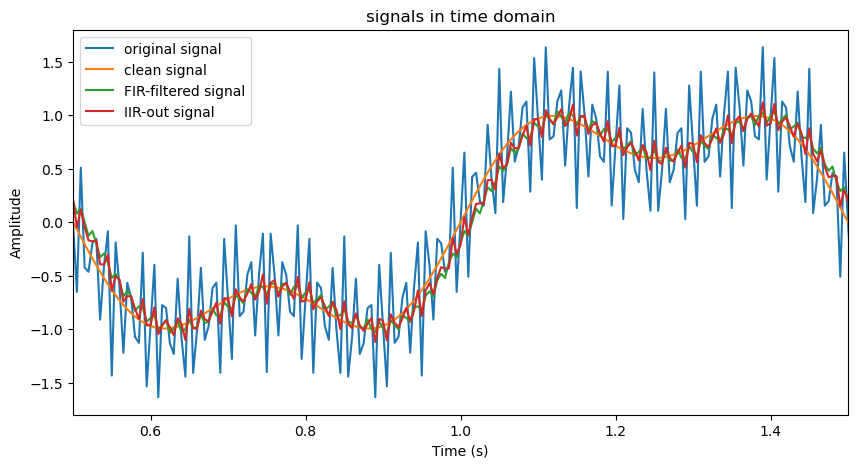

In [17]:
fs = 200
duration = 3
N = fs * duration
t = np.arange(N) / fs

# Simulated useful angular velocity
clean = (np.sin(2*np.pi*1*t) + 0.4*np.sin(2*np.pi*3*t))

# High-frequency sensor interference
noise = (0.5*np.sin(2*np.pi*65*t) + 0.3*np.sin(2*np.pi*85*t))

x = clean + noise

# Selected FIR
b_fir = np.ones(7) / 7

# IIR candidate
alpha = 0.7
b_iir = np.array([1-alpha])
a_iir = np.array([1, -alpha])

fir_out = lfilter(b_fir, [1], x)
iir_out = lfilter(b_iir, a_iir, x)
plt.figure(figsize=(10, 5))
plt.plot(t, x, label = "original signal")
plt.plot(t, clean, label = "clean signal")
plt.plot(t, fir_out, label = "FIR-filtered signal")
plt.plot(t, iir_out, label = "IIR-out signal")
plt.legend()
plt.xlim(0.5, 1.5)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("signals in time domain")
plt.show()

In order to measure which filtered signal is closer to the ideal clean signal we can use RMSE (Root Mean Square Error)

In [18]:
mask = (t >= 0.5) & (t <= 1.5)

fir_rmse = np.sqrt(np.mean((fir_out[mask] - clean[mask]) ** 2))
iir_rmse = np.sqrt(np.mean((iir_out[mask] - clean[mask]) ** 2))

print(f"FIR RMSE = {fir_rmse:.4f}")
print(f"IIR RMSE = {iir_rmse:.4f}")

FIR RMSE = 0.1134
IIR RMSE = 0.1149


The FIR filter has a slightly lower RMSE, meaning its output is closer to the ideal clean signal over the interval you tested. However, the difference is very small.

I would choose the seven-tap FIR filter because it satisfies all three requirements. It also has a slightly lower RMSE than the first-order IIR filter, meaning its output is closer to the ideal clean signal. Although the IIR filter has a shorter group delay, it does not satisfy the amplitude requirements.

One important limitation to mention is that the FIR filter's 15 ms group delay is exactly at our maximum acceptable limit.